# Introduction to Google Colab + Simple Linear Regression

In this notebook you will:
1. Create or verify a Google account.
2. Learn **how to open Google Colab from Gmail**.
3. Run your first cells and install libraries if needed.
4. Complete a **simple linear regression** task (predict apartment price from floor area).
5. Save results and **publish the project on GitHub**.


## 1) Google account — quick setup
- Go to [accounts.google.com/signup](https://accounts.google.com/signup).
- Fill in the form and **create a Google account** (or simply sign in if you already have one).
- After signing in, open **Gmail**: [mail.google.com](https://mail.google.com).

## 2) How to find **Google Colab** from Gmail
1. In Gmail, click the **Google apps menu** (9-dot icon in the top-right corner).
2. In the app grid, click **Colab**.
   > If Colab is missing: choose **“More from Google”** or open **https://colab.research.google.com** in the address bar.
3. In Colab choose: **File → Upload notebook** and upload `colab_regression.ipynb` from this project.

> Tip: alternatively use **File → Save a copy in Drive** and work on the copy in your Google Drive.


## 3) Colab basics
- **Markdown** cells (like this one) are for text and formatting.
- **Code** cells run Python.
- Run a cell with **Ctrl+Enter** (or **Shift+Enter** to run and move to the next cell).
- On the left you can open the **Files** panel and upload data (e.g. CSV).

Below we check the Python version and install libraries if needed.


In [ ]:
import sys, platform
print("Python version:", sys.version)
print("Platform:", platform.platform())


Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Platform: Linux-6.6.122+-x86_64-with-glibc2.39


## 4) Install libraries (only if needed)
In Colab most libraries are already available. If something is missing, use `pip`:


In [ ]:
# Uncomment if you need to install packages locally or in a custom environment:
# !pip install numpy pandas scikit-learn matplotlib


## 5) Data: `apartments.csv`
The project includes a sample file with **floor area (m²)** and **price (thousands of PLN)**.

Option A — load a local file (in Colab open **Files**, upload `apartments.csv`, then run the next cell):


In [ ]:
import pandas as pd

# If you uploaded the file in Colab (Files panel on the left), this path should work:
df = pd.read_csv("apartments.csv")
df.head()


,area_m2,price_thousands_pln
0,35,310
1,42,355
2,50,395
3,57,430
4,65,470


**Option B — file on GitHub:** after publishing the repository, open `apartments.csv` on GitHub, click **Raw**, copy the URL, then:


In [ ]:
# Example (replace with your own GitHub RAW URL):
# raw_url = "https://raw.githubusercontent.com/<your-user>/<your-repo>/main/apartments.csv"
# df = pd.read_csv(raw_url)
# df.head()


## 6) Simple linear regression
Goal: predict **price (thousands of PLN)** from **floor area (m²)**.
Steps:
1. Split features X (area) and target y (price).
2. Fit `LinearRegression`.
3. Inspect parameters (coefficient and intercept).
4. Plot the fitted line.


Coefficient (a): 5.435187608739161
Intercept (b): 122.55816101864565
For 40 m² -> Linear: 340.0k PLN | Polynomial: 338.9k PLN
For 60 m² -> Linear: 448.7k PLN | Polynomial: 449.4k PLN
For 80 m² -> Linear: 557.4k PLN | Polynomial: 558.5k PLN
For 100 m² -> Linear: 666.1k PLN | Polynomial: 666.2k PLN
Mean Absolute Error: 5.61 thousand PLN
Root Mean Squared Error: 5.72 thousand PLN


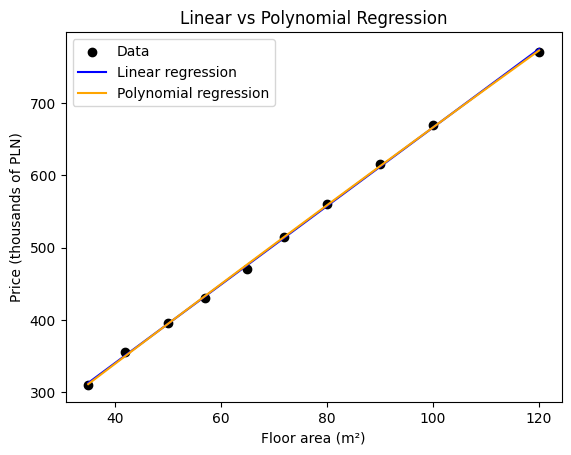

In [17]:
import numpy as np
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt

# for extension
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error

# X: floor area (m²), y: price (thousands of PLN)
df["price_per_m2"] = df["price_thousands_pln"] / df["area_m2"]
df["area_m2_squared"] = df["area_m2"] ** 2

y = df["price_thousands_pln"].values

X_lin = df[["area_m2"]].values
X_poly = df[["area_m2", "area_m2_squared"]].values

model_lin = LinearRegression()
model_lin.fit(X_lin, y)

model_poly = LinearRegression()
model_poly.fit(X_poly, y)

print("Coefficient (a):", model_lin.coef_[0])
print("Intercept (b):", model_lin.intercept_)

# Predictions for a few sample areas
sample_areas = np.array([40, 60, 80, 100])

sample_lin = sample_areas.reshape(-1, 1)
pred_lin = model_lin.predict(sample_lin)

sample_poly = np.column_stack([sample_areas, sample_areas**2])
pred_poly = model_poly.predict(sample_poly)

for m2, p_lin, p_poly in zip(sample_areas, pred_lin, pred_poly):
  print(f"For {m2} m² -> Linear: {p_lin:.1f}k PLN | Polynomial: {p_poly:.1f}k PLN")

# Plot: points + regression line
x_area = np.linspace(df["area_m2"].min(), df["area_m2"].max(), 100)

y_line_lin = model_lin.predict(x_area.reshape(-1, 1))

x_line_poly = np.column_stack([x_area, x_area ** 2])
y_line_poly = model_poly.predict(x_line_poly)

#extension
X_train, X_test, y_train, y_test = train_test_split(
    X_poly, y, test_size=0.2, random_state=42
)
model_poly.fit(X_train, y_train)
y_pred = model_poly.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
print(f"Mean Absolute Error: {mae:.2f} thousand PLN")
print(f"Root Mean Squared Error: {rmse:.2f} thousand PLN")

plt.figure()
plt.scatter(df["area_m2"], y, color="black", label="Data")

plt.plot(x_area, y_line_lin, color="blue", label="Linear regression")
plt.plot(x_area, y_line_poly, color="orange", label="Polynomial regression")

plt.xlabel("Floor area (m²)")
plt.ylabel("Price (thousands of PLN)")
plt.title("Linear vs Polynomial Regression")
plt.legend()

plt.savefig("regression.png")

plt.show()


### Your exercises
1. Add a new column with **price per m²** (`price_per_m2`) and inspect how it changes across areas.
2. Add mild non-linearity (e.g. `area_m2^2` as an extra feature) and check whether the error decreases.
3. Save the plot as PNG (e.g. `plt.savefig("regression.png")`).

> Extension: split into **train/test** (`train_test_split`) and compute error metrics (e.g. MAE, RMSE).


## 7) Saving and sharing the notebook
- **File → Save a copy in GitHub** — choose repository and folder.
- **File → Download .ipynb** — download the notebook and upload it manually to GitHub.

## 8) Publish the whole project on GitHub (web UI)
1. Sign in at [github.com](https://github.com).
2. Click **New** and create a repository (e.g. `colab-regression`).
3. Drag and drop project files: `colab_regression.ipynb`, `apartments.csv`, `README.md`, `requirements.txt`, `.gitignore`.
4. Click **Commit changes**.
5. Open `colab_regression.ipynb` and check the preview. Optionally copy the **RAW URL** of `apartments.csv` for Option B above.

> Alternative (git in a terminal):
> ```bash
> git init
> git add .
> git commit -m "Initial commit: Colab + linear regression"
> git branch -M main
> git remote add origin https://github.com/<your-user>/<your-repo>.git
> git push -u origin main
> ```


---
Done! You can open **Colab from Gmail**, run code, complete a simple **linear regression**, and **publish the project on GitHub**.
Good luck!
